# Markov Chains and Tumor Heterogeneity


## Background

Why are tumors so hard to treat? Why have we been fighting the "War on Cancer" for over 50 years? 

One key reason is that a tumor isn't made up of a single kind of cell. If it was, we could find a single drug that would target said cell, and kill all of them, without them coming back. However, most tumors are mixes of different types of cancer cells. A breast cancer tumor will only contain breast tumor cells, but those breast tumor cells may be clustered in different states-- some of which are sensitive to drugs, some of which are naturally resistant, and some of which can transition from one state to another. In fact, drug treatment is often the *force* that helps tumor cells transition from sensitive to resistant, meaning the treatment itself is worsening the disease it is trying to treat.

## The lab goal: 
>**Simulate a patient's tumor and figure out what combination of drugs is likely to be effective at killing the tumor.**

If we can track how cells change state *within a single tumor* under drugs, then we can predict what might happen to a patient treated with said drug. To answer that we need to know **how often a cell in each state moves to each other state during one treatment cycle**. That is a transition matrix, and a transition matrix lets us forecast what any tumor looks like after many cycles.

In this lab you will:
   
1. **Build a transition matrix.** Use lineage tags to match each cell at time point A to its descendant at time point B, then count and normalize.
2. **Evolve a distribution.** Start from each single state, and from a mixed tumor, and see where each one ends up.
3. **Simulate random walks and whole tumors.** Follow individual cells by drawing random numbers, then simulate many tumors to estimate how likely each one is to be cured or to relapse.
4. **Find which tumors each drug can cure**, and see why a mixed tumor can't be cured by either drug alone.


Note: **The data is simulated.** The states and their marker genes are modelled on PC9 cells (Oren et al. 2021, *Nature* 596:576), but every count was generated by a script, and how each state responds to each drug is vastly simplified.

## The data

**A little background:**

Lung cancer cells carry a mutant EGFR gene and depend on it to grow. We compare two
drugs:

- **osimertinib**, which blocks EGFR, and
- **docetaxel**, a chemotherapy that kills cells while they divide.
- We will also look at how the cells evolve under no treatment ("drug holiday")

You do not need to understand biology or cancer to complete this lab; the key thing is you have drugs with different effects on cells within a single tumor.

**The dataset:**

Every cell carries something called a  **lineage tag**: a short DNA barcode inserted into its genome, inherited by its descendants. For each drug, one sample is:

1. sequenced at **time point A**, before treatment;
2. treated for **one cycle**;
3. sequenced again at **time point B**.

A tag that appears at both time points links a cell at A to its descendant at B. **A tag seen at A but missing at B means that cell died.** We make one big simplifying assumption: each tag maps one cell at A to *at most one* cell at B.


In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

rng = np.random.default_rng(5030)
plt.rcParams["figure.dpi"] = 110

In [2]:
STATE_ORDER = ["S-G1", "S-syn", "S-G2M", "P",
           "NCP", "CP", "MDR"] 
STATE_COLORS = dict(zip(STATE_ORDER, sns.color_palette("Set2", len(STATE_ORDER))))
STATE_COLORS["cleared"] = "#8a8984"  

In [5]:
cells = pd.read_csv("cell_data.csv")
cells.head()

,Unnamed: 0,experiment,timepoint,lineage_tag,umap_x,umap_y,state
0,0,osimertinib,A,tago-02305,12.879967,12.534007,S-G1
1,1,osimertinib,B,tago-01560,-1.712741,11.650750,P
2,2,osimertinib,A,tago-02253,12.870441,12.998882,S-G1
3,3,osimertinib,A,tago-01478,15.319292,1.937557,S-syn
4,4,osimertinib,A,tago-02626,13.258777,12.765258,S-G1


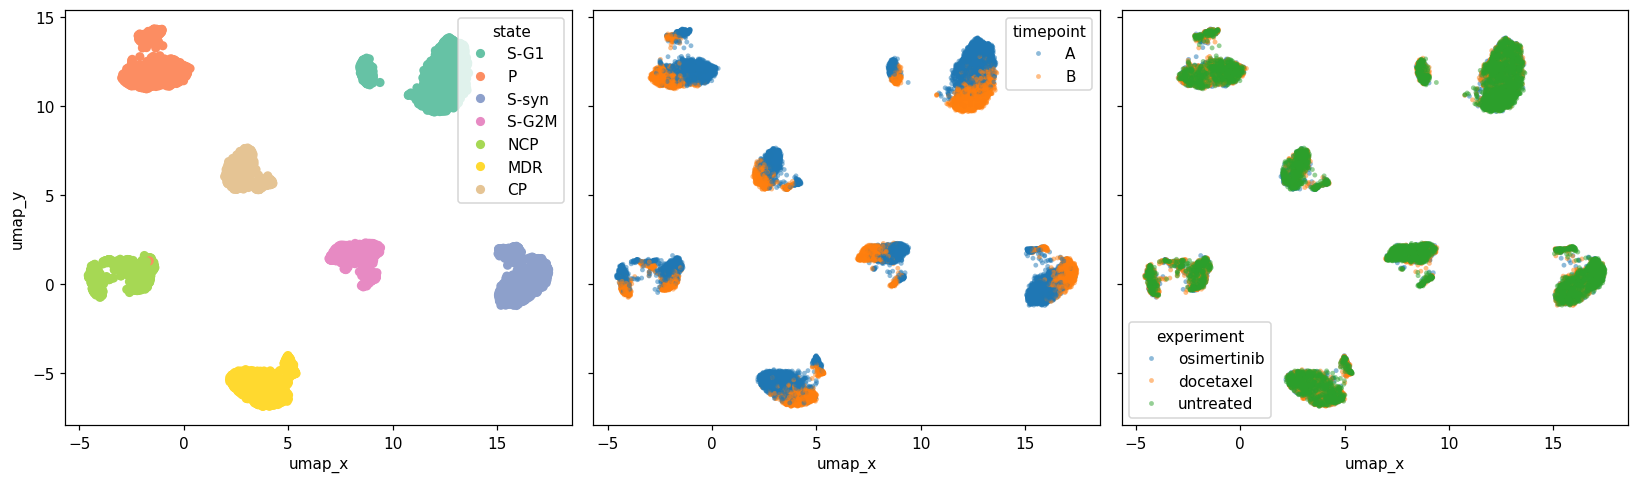

In [6]:
import seaborn as sns
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5), sharex=True, sharey=True)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "state", ax = axes[0], palette = "Set2", linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "timepoint", ax = axes[1],s=10, alpha=0.5, linewidth=0)
sns.scatterplot(cells, x = "umap_x", y ="umap_y", hue = "experiment", ax = axes[2],s=10, alpha=0.5, linewidth=0)
plt.tight_layout()
plt.show()

<img src="state_diagram_v2.png">

## 2. Build the transition matrix for the Osimertinib experiment

Start with the osimertinib experiment.

A transition matrix $P$ has one row per state at time point A and one column
per state at time point B:

$$
P_{ij} \;=\; \Pr[\,X_{t+1} = j \mid X_t = i\,]
\;\approx\; \frac{\#\{\text{cells in state } i \text{ at A whose tag is in state } j \text{ at B}\}}
                 {\#\{\text{cells in state } i \text{ at A}\}}.
$$

In the code below, we will start with just the osimertinib experiment (timepoints A and B), and look at where each tag was in A and where it moved to in B. 

**Where does a cell that died end up?** We add an eighth outcome, `"cleared"`, for tags present at A and missing at B.

In [7]:
osi = cells[cells["experiment"] == "osimertinib"]
at_A = osi[osi.timepoint == "A"][["lineage_tag", "state"]]
at_B = osi[osi.timepoint == "B"][["lineage_tag", "state"]]

pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
pairs["state_B"] = pairs["state_B"].fillna("cleared")

pairs.head()

,lineage_tag,state_A,state_B
0,tago-02305,S-G1,cleared
1,tago-02253,S-G1,cleared
2,tago-01478,S-syn,NCP
3,tago-02626,S-G1,P
4,tago-01487,P,P


In [8]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]   # states in a fixed order
OUTCOMES = STATES + ["cleared"]
counts = (pd.crosstab(pairs.state_A, pairs.state_B)
            .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
P_hat = counts.div(counts.sum(axis=1), axis=0)

In [9]:
assert np.allclose(P_hat.sum(axis=1), 1), "Every row should sum to 1."


In [10]:
print("transition counts:")
display(counts)
print("estimated transition matrix (osimertinib, one cycle):")
P_hat.round(3)

transition counts:


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,91,17,11,154,41,0,0,437
S-syn,27,23,17,38,16,0,0,333
S-G2M,8,13,20,20,0,0,0,219
P,47,11,8,160,75,0,0,154
NCP,19,0,0,31,153,0,0,109
CP,0,0,0,0,0,279,0,0
MDR,20,14,10,14,0,0,82,329


estimated transition matrix (osimertinib, one cycle):


state_B,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
state_A,,,,,,,,
S-G1,0.121,0.023,0.015,0.205,0.055,0.0,0.000,0.582
S-syn,0.059,0.051,0.037,0.084,0.035,0.0,0.000,0.733
S-G2M,0.029,0.046,0.071,0.071,0.000,0.0,0.000,0.782
P,0.103,0.024,0.018,0.352,0.165,0.0,0.000,0.338
NCP,0.061,0.000,0.000,0.099,0.490,0.0,0.000,0.349
CP,0.000,0.000,0.000,0.000,0.000,1.0,0.000,0.000
MDR,0.043,0.030,0.021,0.030,0.000,0.0,0.175,0.701


Because some of the cells die and get cleared, we added an extra state they could move to. To use this transition matrix over and over again (for example, if a patient got two rounds of osimertinib), we need it to have the *same* rows and columns-- **the transition matrix should be able to tell us where a cell moves to for *any state at all, including "cleared."*** So we will **add another row to the transition matrix:** if a cell starts in "cleared" it stays cleared with probability = 1.

### Make it square

We add that row by **assumption**: a cleared cell stays cleared with probability 1. A state you can never leave is called an **absorbing state**.

In [11]:
#add a cleared row that stays cleared with p = 1
P_hat.loc["cleared"] = pd.Series({rowname: (1 if rowname == "cleared" else 0) for rowname in P_hat.columns})

In [12]:
STATES = [s for s in STATE_ORDER if s in set(cells["state"])]
OUTCOMES = STATES + ["cleared"]

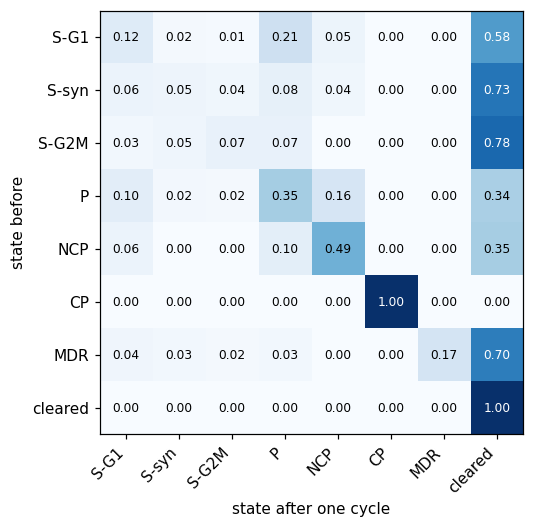

In [13]:
def show_matrix(P, title=None, ax=None):
    ax = ax or plt.subplots(figsize=(6.5, 5))[1]
    values = P.to_numpy()                      # numbers for imshow and P[i, j]
    ax.imshow(values, cmap="Blues", vmin=0, vmax=1)
    for i in range(values.shape[0]):
        for j in range(values.shape[1]):
            ax.text(j, i, f"{values[i, j]:.2f}", ha="center", va="center",
                    color="white" if values[i, j] > 0.5 else "black", fontsize=8)
    ax.set_xticks(range(values.shape[1]), P.columns, rotation=45, ha="right")
    ax.set_yticks(range(values.shape[0]), P.index)
    ax.set_xlabel("state after one cycle"); ax.set_ylabel("state before")
    ax.set_title(title)

show_matrix(P_hat)

<div class='alert alert-info'>
<b>Question:</b> reading P_hat and looking at the matrix, are any of the measured states other than "cleared" also (approximately) absorbing under osimertinib? If so, what does this mean in terms of the response to drug treatment? If not, what does it mean?
</div>

*Answer here.*
Yes, CP has a probability of 1.0 meaning that from time A to time B none of the CP cells died. This means that under osimertinib CP is absorbing. This means the drug cannot kill   CP cells.

## 3. Simulate a tumor comprising 1 cell type: Evolve a distribution

Write the state of the whole tumor as a **row vector** $\pi_t$: entry $j$ is the
probability that a randomly chosen original cell is in state $j$ after $t$
cycles. One cycle multiplies by $P$:

$$
\pi_{t+1} = \pi_t P
\qquad\Longrightarrow\qquad
\pi_t = \pi_0 P^t .
$$

Start with the simplest $\pi_0$: a **basis vector**, all probability on one
state. $e = (1, 0, 0, 0, 0, 0, 0, 0)$ asks "what happens to a
cell that starts in state S-G1?" Equivalently, "what happens to a tumor made entirely of S-G1 cells?"

**Predict first.** Before running the code: look at the transition matrix: which starting states can osimertinib eliminate completely? Which can't it? 

In [16]:
def evolve(pi0, P, n_cycles):
    '''Return an array of shape (n_cycles + 1, n_states) whose row t is pi0 @ P^t.'''
    traj = [np.asarray(pi0, dtype=float)]
    for _ in range(n_cycles):
        traj.append(traj[-1] @ P)
    return np.array(traj)

In [17]:
def basis(starting_state, P):
    '''All probability on one state, named as in P's columns.'''
    names = list(P.columns)
    e = np.zeros(len(names))
    e[names.index(starting_state)] = 1.0
    return e

basis("S-G1", P_hat)

array([1., 0., 0., 0., 0., 0., 0., 0.])

### What happens after many rounds of a single treatment?
We are going to run 8 rounds of treatment. A typical course of chemotherapy is 4 to 8 rounds, so this is on the higher end. With 8 rounds, do we clear all of the cancer cells?

In [18]:
traj = evolve(basis("S-G1", P_hat), P_hat, 8)
pd.DataFrame(traj, columns=OUTCOMES).round(3)

,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,1.000,0.000,0.000,0.000,0.000,0.0,0.0,0.000
1,0.121,0.023,0.015,0.205,0.055,0.0,0.0,0.582
2,0.041,0.010,0.007,0.105,0.068,0.0,0.0,0.769
3,0.021,0.004,0.003,0.054,0.053,0.0,0.0,0.865
4,0.012,0.002,0.002,0.029,0.036,0.0,0.0,0.919
5,0.007,0.001,0.001,0.016,0.023,0.0,0.0,0.951
6,0.004,0.001,0.000,0.010,0.015,0.0,0.0,0.971
7,0.002,0.000,0.000,0.006,0.009,0.0,0.0,0.982
8,0.001,0.000,0.000,0.003,0.005,0.0,0.0,0.989


The output of the evolve function is a dataframe where columns are the states and each row is the distribution of probability after that many cycles. We can also visualize this in the plots below. 

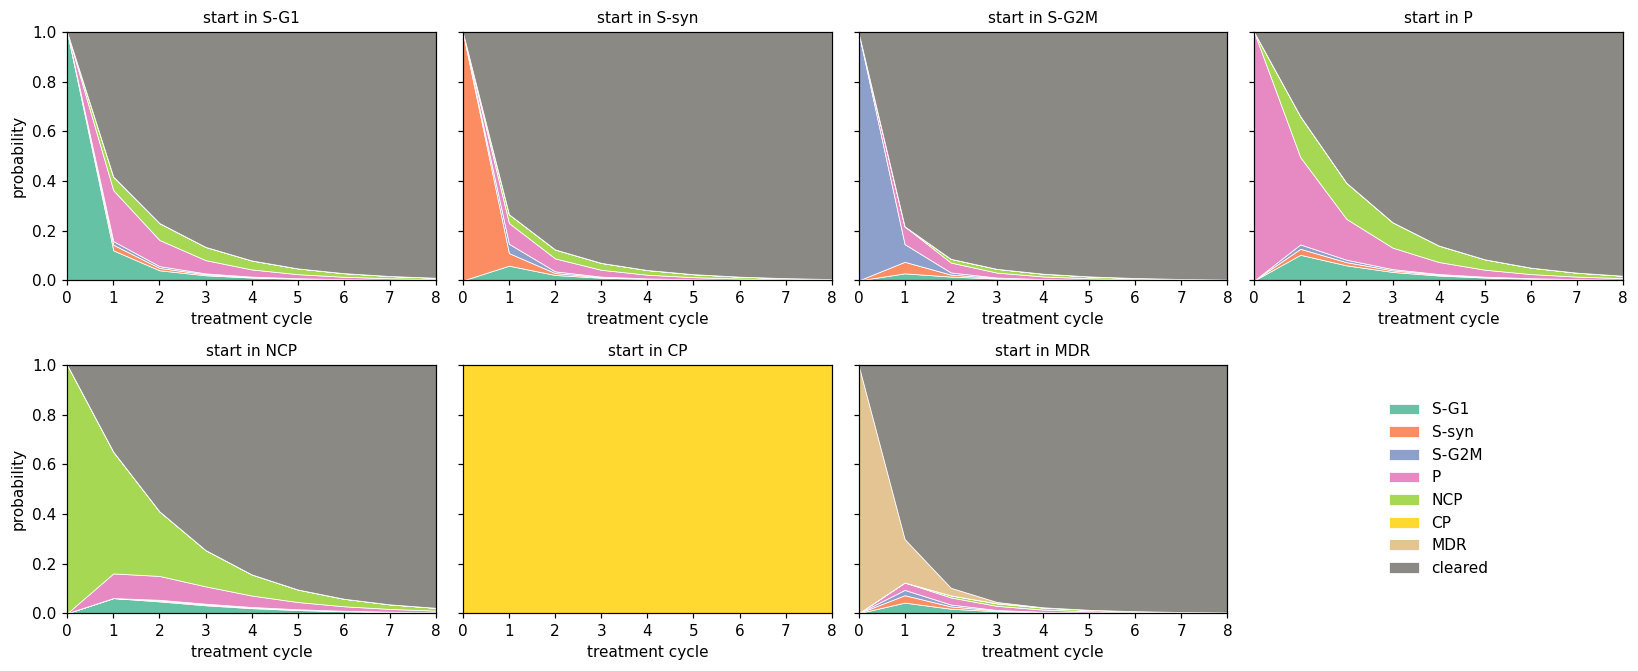

fraction alive after 4 cycles, starting in S-G1 : 0.081
fraction alive after 4 cycles, starting in S-syn : 0.042
fraction alive after 4 cycles, starting in S-G2M : 0.027
fraction alive after 4 cycles, starting in P : 0.141
fraction alive after 4 cycles, starting in NCP : 0.156
fraction alive after 4 cycles, starting in CP : 1.0
fraction alive after 4 cycles, starting in MDR : 0.024
fraction alive after 4 cycles, starting in cleared : 0.0


In [19]:
def plot_trajectory(traj, ax, title):
    t = np.arange(len(traj))
    ax.stackplot(t, traj.T, labels=OUTCOMES, colors=[STATE_COLORS[o] for o in OUTCOMES],
                 edgecolor="white", linewidth=0.5)
    ax.set_xlim(0, t[-1]); ax.set_ylim(0, 1)
    ax.set_title(title, fontsize=10); ax.set_xlabel("treatment cycle")

N_CYCLES = 8
fig, axes = plt.subplots(2, 4, figsize=(15, 6.2), sharey=True)
for ax, s in zip(axes.flat, STATES):
    plot_trajectory(evolve(basis(s, P_hat), P_hat, N_CYCLES), ax, f"start in {s}")

axes.flat[-1].axis("off")                                   # 7 states, 8 panels: use the last one for the legend
handles, labels = axes.flat[0].get_legend_handles_labels()
axes.flat[-1].legend(handles, labels, loc="center", frameon=False)

for ax in axes[:, 0]:
    ax.set_ylabel("probability")
plt.tight_layout()
plt.show()

alive3 = {s: 1 - evolve(basis(s, P_hat), P_hat, 4)[-1, -1] for s in OUTCOMES}
for s,v in alive3.items():
    print("fraction alive after 4 cycles, starting in", s, ":", round(v, 3))

<div class='alert alert-info'>
Use code as appropriate to answer the following questions.

- Which starting states does osimertinib completely eliminate (all probability ends in `cleared`)? Which ones survive?
- Of the states that can be cleared, which tumor lasts the longest?
- Which starting state sticks around for the most cycles of drug?
- Which starting state results in the highest proportion of alive cells after three cycles?</div>



Every state except CP is eventually cleared. S-G1, S-syn, S-G2M, P, NCP and MDR can only lead to one another or to cleared, and none of them can reach CP. So all their probability ends up in cleared as t approaches infinity.



NCP and then P. NCP has the highest self-transition among the clearable states (0.49), and some of it moves to P (0.10), which also persists (0.35). It has the most expected cycles alive (2.72), the most still alive at 8 cycles (2.2%), and is the slowest to drop below 0.1% (15 cycles).

CP because it never leaves and never dies. 

CP, with 1.0 alive. Among clearable states it's NCP (0.254), then P (0.234). The fastest to clear are MDR (0.045) and S-G2M (0.047).

### Starting from a mix of cell types
Use the distribution of states in timepoint A across all three experiments as a starting vector, $\pi_{0}$. Use this as your starting vector to evolve, and plot the result.

S-G1       0.247
S-syn      0.148
S-G2M      0.099
P          0.153
NCP        0.102
CP         0.097
MDR        0.153
cleared    0.000
dtype: float64


,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.070,0.026,0.022,0.139,0.094,0.097,0.027,0.525
2,0.032,0.008,0.007,0.077,0.074,0.097,0.005,0.701
3,0.017,0.003,0.003,0.042,0.051,0.097,0.001,0.786
4,0.010,0.002,0.001,0.024,0.033,0.097,0.000,0.833
5,0.006,0.001,0.001,0.014,0.021,0.097,0.000,0.861
6,0.003,0.001,0.000,0.008,0.013,0.097,0.000,0.877
7,0.002,0.000,0.000,0.005,0.008,0.097,0.000,0.887
8,0.001,0.000,0.000,0.003,0.005,0.097,0.000,0.893


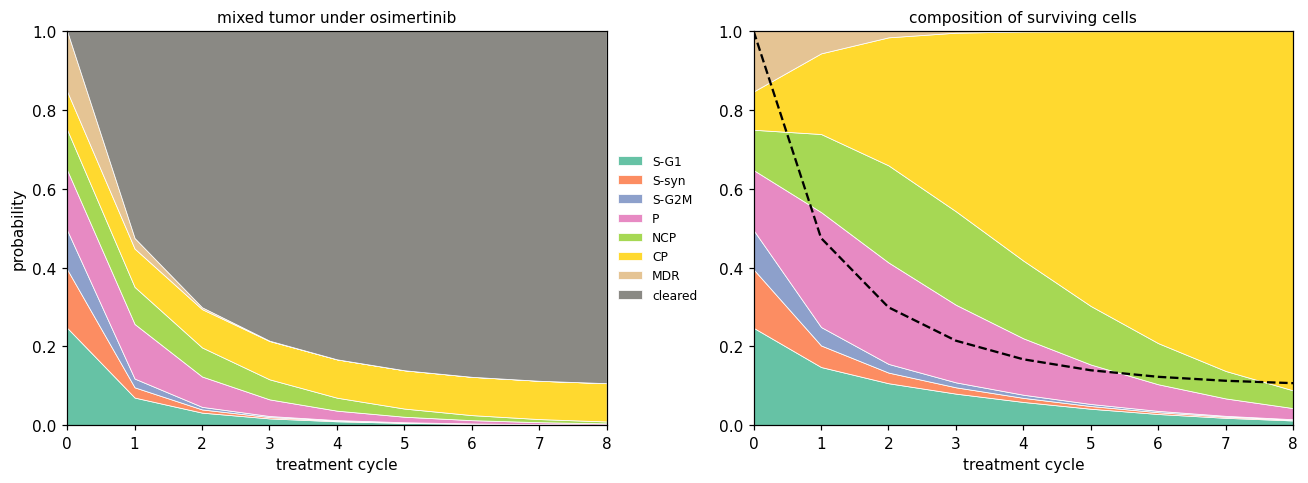

In [ ]:

at_A_all = cells[cells["timepoint"] == "A"]
pi_mix = (at_A_all["state"]
          .value_counts(normalize=True)
          .reindex(OUTCOMES, fill_value=0)   # puts states in OUTCOMES order; cleared = 0
          .to_numpy())

print(pd.Series(pi_mix, index=OUTCOMES).round(3))


traj_mix = evolve(pi_mix, P_hat, N_CYCLES)
display(pd.DataFrame(traj_mix, columns=OUTCOMES).round(3))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))


plot_trajectory(traj_mix, axes[0], "mixed tumor under osimertinib")
axes[0].set_ylabel("probability")
axes[0].legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)

alive_frac = 1 - traj_mix[:, -1]
survivors = traj_mix[:, :-1] / alive_frac[:, None]
t = np.arange(N_CYCLES + 1)
axes[1].stackplot(t, survivors.T, labels=STATES,
                  colors=[STATE_COLORS[s] for s in STATES],
                  edgecolor="white", linewidth=0.5)
axes[1].plot(t, alive_frac, "k--", lw=1.5, label="fraction alive")
axes[1].set_xlim(0, N_CYCLES); axes[1].set_ylim(0, 1)
axes[1].set_title("composition of surviving cells", fontsize=10)
axes[1].set_xlabel("treatment cycle")

plt.tight_layout()
plt.show()



<div class = "alert alert-info"> Which state ends up dominating the remaining cluster? Will these cells ever be cleared? How does the long-run endpoint relate to the transition matrix?</div>

CP ends up dominating the remaining cluster. It grows from about 10% of the starting tumor to over 90% of the surviving cells after 8 cycles, because osimertinib clears every other state but never touches CP. These cells will never be cleared under osimertinib, since P(CP -> CP) = 1 and P(CP -> cleared) = 0. The long-run endpoint comes from the matrix's two absorbing states, CP and cleared: all the transient states drain into cleared, and no state moves into CP. 

## 4. Transition matrices for docetaxel and the drug holiday

Using the same approach in step 2 and step 3, answer the following questions.

1. What is the transition matrix under docetaxel and drug holiday, and how do they compare to osimertinib? Are there any absorbing states?
2. Simulate the mixed tumor under multiple rounds of docetaxel. What happens?

In [21]:
##Add code here
# keep these as 8x8 numpy arrays (with the cleared row): the random walks index rows by position
def transition_matrix(experiment):
    '''Estimate the 8x8 transition matrix (with an absorbing cleared row) for one experiment.'''
    d = cells[cells["experiment"] == experiment]
    at_A = d[d.timepoint == "A"][["lineage_tag", "state"]]
    at_B = d[d.timepoint == "B"][["lineage_tag", "state"]]
    pairs = pd.merge(at_A, at_B, on="lineage_tag", how="left", suffixes=("_A", "_B"))
    pairs["state_B"] = pairs["state_B"].fillna("cleared")
    counts = (pd.crosstab(pairs.state_A, pairs.state_B)
                .reindex(index=STATES, columns=OUTCOMES, fill_value=0))
    P = counts.div(counts.sum(axis=1), axis=0)
    P.loc["cleared"] = [1 if o == "cleared" else 0 for o in OUTCOMES]
    assert np.allclose(P.sum(axis=1), 1)
    return P

P_doc_df     = transition_matrix("docetaxel")
P_holiday_df = transition_matrix("untreated")

P_osi     = P_hat.to_numpy()
P_doc     = P_doc_df.to_numpy()
P_holiday = P_holiday_df.to_numpy()

# Absorbing (or nearly absorbing) states: diagonal entries close to 1
for name, P in [("osimertinib", P_hat), ("docetaxel", P_doc_df), ("holiday", P_holiday_df)]:
    diag = pd.Series(np.diag(P), index=P.index)
    print(f"{name:12s} self-transition probabilities:\n{diag.round(3).to_string()}\n")


osimertinib  self-transition probabilities:
state_A
S-G1       0.121
S-syn      0.051
S-G2M      0.071
P          0.352
NCP        0.490
CP         1.000
MDR        0.175
cleared    1.000

docetaxel    self-transition probabilities:
state_A
S-G1       0.293
S-syn      0.111
S-G2M      0.035
P          0.409
NCP        0.436
CP         0.100
MDR        1.000
cleared    1.000

holiday      self-transition probabilities:
state_A
S-G1       0.412
S-syn      0.342
S-G2M      0.269
P          0.324
NCP        0.478
CP         0.820
MDR        0.542
cleared    1.000



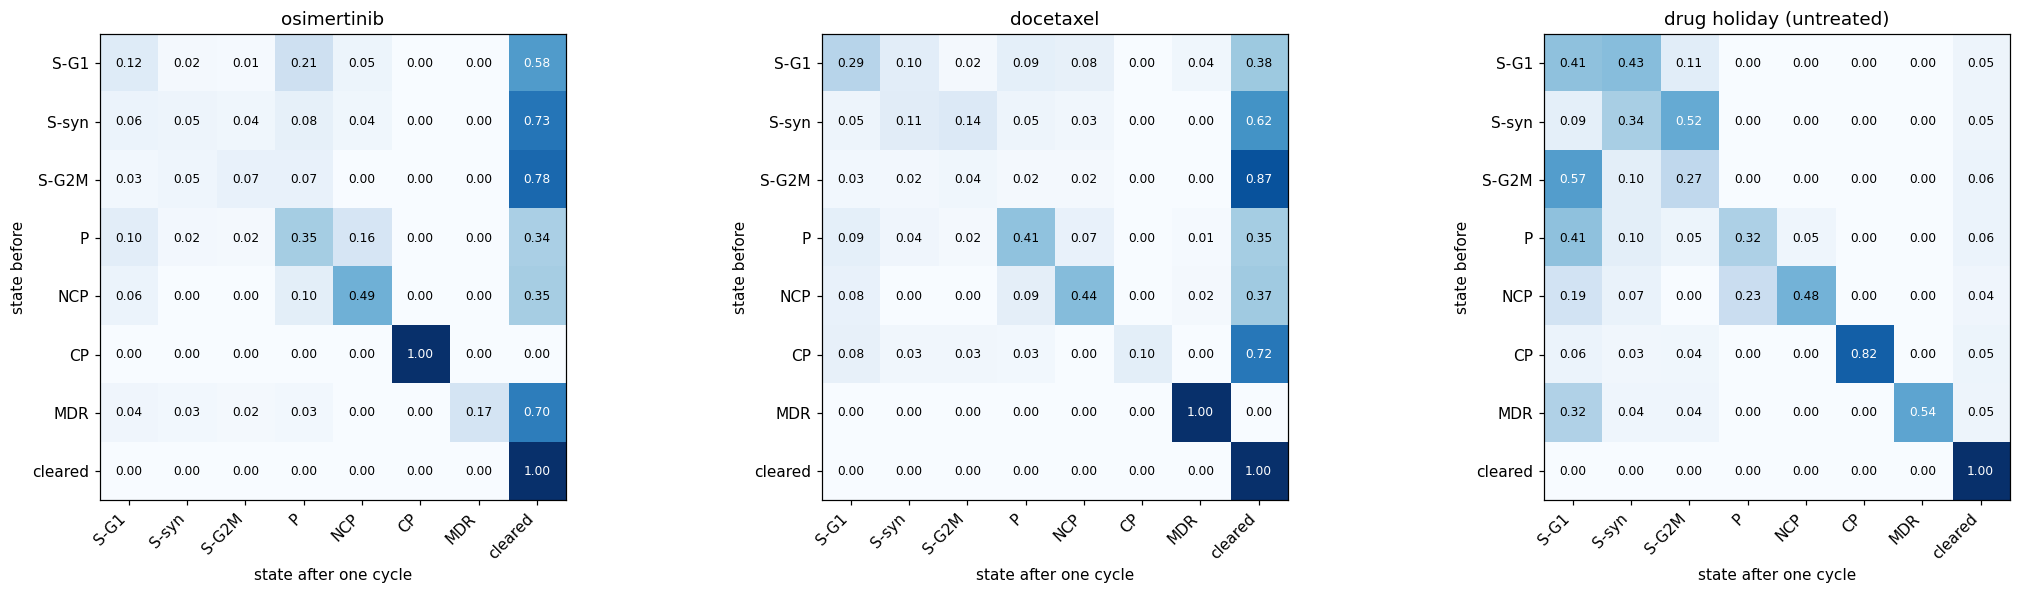

In [22]:
#Plot the transition matrices for docetaxel and the drug holiday.
fig, axes = plt.subplots(1, 3, figsize=(20, 5.5))
show_matrix(P_hat,        "osimertinib",            axes[0])
show_matrix(P_doc_df,     "docetaxel",              axes[1])
show_matrix(P_holiday_df, "drug holiday (untreated)", axes[2])
plt.tight_layout()
plt.show()



,S-G1,S-syn,S-G2M,P,NCP,CP,MDR,cleared
0,0.247,0.148,0.099,0.153,0.102,0.097,0.153,0.000
1,0.112,0.054,0.036,0.107,0.083,0.010,0.166,0.434
2,0.053,0.023,0.014,0.065,0.055,0.001,0.174,0.615
3,0.027,0.011,0.006,0.038,0.034,0.000,0.178,0.705
4,0.015,0.006,0.003,0.022,0.020,0.000,0.180,0.754
5,0.008,0.003,0.002,0.013,0.012,0.000,0.181,0.781
6,0.005,0.002,0.001,0.007,0.007,0.000,0.182,0.797
7,0.003,0.001,0.001,0.004,0.004,0.000,0.182,0.805
8,0.002,0.001,0.000,0.002,0.002,0.000,0.183,0.810


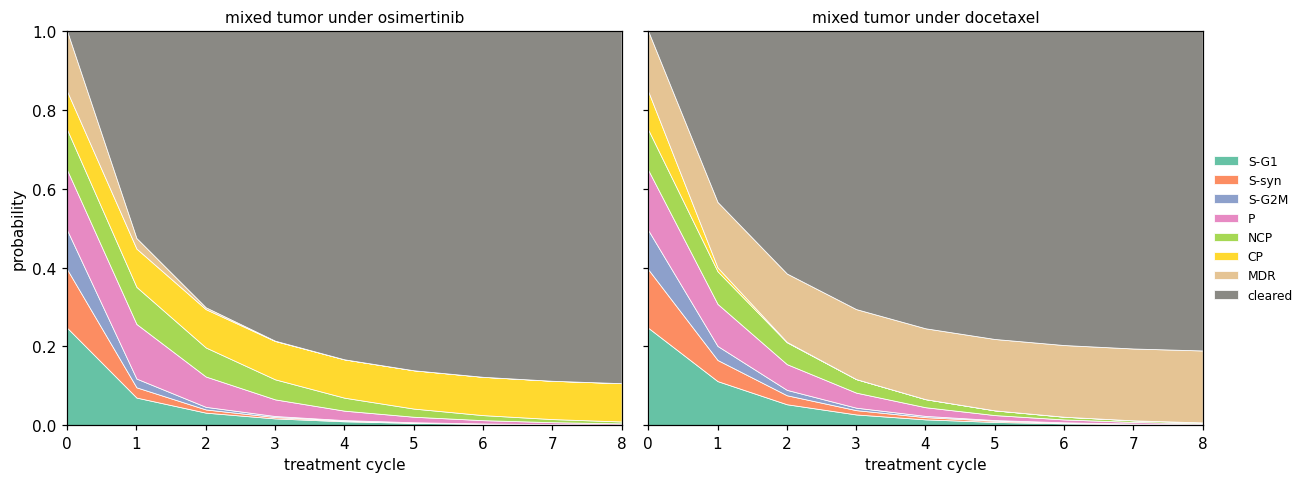

fraction alive after 8 cycles:  osimertinib 0.107 | docetaxel 0.19


In [23]:
# Simulate the evolution of pi_mix under docetaxel 
traj_doc = evolve(pi_mix, P_doc, N_CYCLES)
display(pd.DataFrame(traj_doc, columns=OUTCOMES).round(3))

traj_osi = evolve(pi_mix, P_osi, N_CYCLES)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
plot_trajectory(traj_osi, axes[0], "mixed tumor under osimertinib")
plot_trajectory(traj_doc, axes[1], "mixed tumor under docetaxel")
axes[0].set_ylabel("probability")
axes[1].legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.tight_layout()
plt.show()

print("fraction alive after 8 cycles:  osimertinib", round(1 - traj_osi[-1, -1], 3),
      "| docetaxel", round(1 - traj_doc[-1, -1], 3))



1. A transition matrix shows where a cell ends up after one round. It answers what group group the cell is in or if it is dead (cleared). A state is absorbing when a cell that enters it never leaves. 
Osimertinib: CP is absorbing. Every CP cell stays CP and none of them die, so this drug can't affect CP at all.

Docetaxel: MDR is the absorbing state. All 454 MDR cells stayed MDR, and none died. CP, the group osimertinib couldn't kill, is easy for docetaxel to kill: about 72% of CP cells die in one round. Docetaxel also turns a small number of other cells into MDR, so it helps create the group it can't kill. The two drugs are mirror images: each one has a group it can't kill, and the other drug kills that group well.

2. The tumor shrinks fast at first: 57% of cells are alive after 1 round, 30% after 3 and 19% after 8. Then it stops shrinking at about 18–19%, because almost all the cells left are MDR, which docetaxel can't kill. MDR ends up making up more of the original tumor than it started with because docetaxel turns some cells into MDR. Meanwhile, the CP cells are gone after about 2 rounds. Neither drug works alone so a combination of both drugs should be used to remove the tumor.



## 5. Drug schedule strategies

We can answer a LOT of questions about what treatment strategy is best, just based on multiplying the transition matrices $P_{osi}, P_{doc},$ and $P_{holiday}$ together. Because matrix multiplication is linear, knowing what happens to the basis vectors under each drug tells us everything we need to know about the possibilities for mixed tumors. Use the transition matrices to do the following, running **8 cycles in each schedule**:
1. Compare 8 rounds of docetaxel and 8 rounds of osimertinib (done in step 4) to an alternating drug schedule.
   - For an alternating schedule, one *pair* of cycles multiplies by $P_{osi} P_{doc}$ and is considered 2 rounds of therapy.
2. Does it matter if we start with osimertinib or docetaxel when alternating treatments for this particular tumor?
3.  In what situation would a drug holiday help clear the tumor?
4. Test different combinations of starting states and treatment plans. Write a treatment prescription based on the general patterns you see. For example, If a tumor is entirely X cell type, treat with X. You do not need to enumerate the entire state space of possibilities, but a few clear strategies should emerge. In your treatment prescription, include the number of rounds of therapy needed. Keep in mind that fewer rounds is always better for patient health, but may not sufficiently clear the tumor. You can write this as a table or a short paragraph, but include your reasoning.

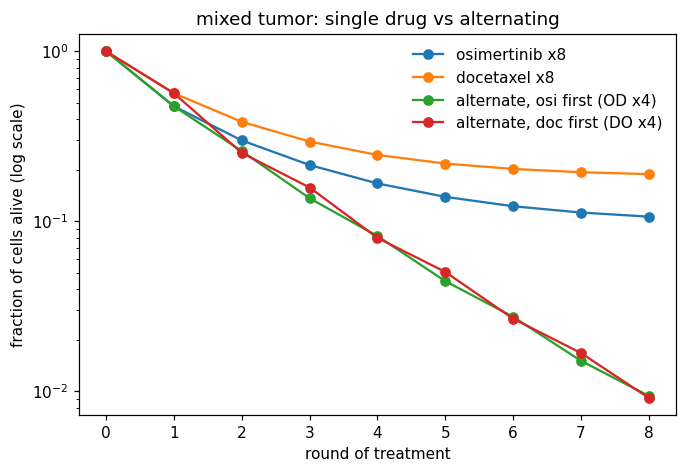

,osimertinib x8,docetaxel x8,"alternate, osi first (OD x4)","alternate, doc first (DO x4)",holiday then osi x7,holiday then doc x7
measured mix,0.1066,0.1896,0.0094,0.0092,0.0926,0.1220
S-G1,0.0108,0.0727,0.0099,0.0109,0.0120,0.0402
S-syn,0.0056,0.0124,0.0051,0.0047,0.0079,0.0163
S-G2M,0.0036,0.0059,0.0032,0.0021,0.0127,0.0490
P,0.0190,0.0545,0.0170,0.0154,0.0204,0.0614
NCP,0.0216,0.0681,0.0190,0.0172,0.0280,0.0677
CP,1.0000,0.0101,0.0064,0.0036,0.8218,0.0154
MDR,0.0029,1.0000,0.0048,0.0073,0.0090,0.5683


,O,D,OD,DO
measured mix,never,never,8,8
S-G1,9,never,8,9
S-syn,7,10,7,7
S-G2M,6,6,6,6
P,10,never,9,9
NCP,10,never,10,10
CP,never,9,8,7
MDR,6,never,7,8


In [24]:
## Add code here

M = {"O": P_osi, "D": P_doc, "H": P_holiday}   # O = osimertinib, D = docetaxel, H = holiday

def run_schedule(pi0, schedule):
    '''schedule is a string such as "ODODODOD": one letter per round, applied left to right.
    Returns the fraction of cells still alive after each round.'''
    pi = np.asarray(pi0, dtype=float)
    alive = [1 - pi[-1]]
    for drug in schedule:
        pi = pi @ M[drug]
        alive.append(1 - pi[-1])
    return np.array(alive)

schedules = {
    "osimertinib x8":   "O" * 8,
    "docetaxel x8":     "D" * 8,
    "alternate, osi first (OD x4)": "OD" * 4,
    "alternate, doc first (DO x4)": "DO" * 4,
}

# Q1 + Q2: the mixed tumor under each schedule
fig, ax = plt.subplots(figsize=(7, 4.5))
for name, sched in schedules.items():
    ax.plot(run_schedule(pi_mix, sched), marker="o", label=name)
ax.set_yscale("log")
ax.set_xlabel("round of treatment"); ax.set_ylabel("fraction of cells alive (log scale)")
ax.set_title("mixed tumor: single drug vs alternating")
ax.legend(frameon=False)
plt.show()

# Q3 + Q4: alive after 8 rounds for every starting state and schedule
schedules_all = {**schedules,
                 "holiday then osi x7": "H" + "O" * 7,
                 "holiday then doc x7": "H" + "D" * 7}
starts = {"measured mix": pi_mix, **{s: basis(s, P_hat) for s in STATES}}
table = pd.DataFrame({name: {start: run_schedule(pi0, sched)[-1] for start, pi0 in starts.items()}
                      for name, sched in schedules_all.items()})
display(table.round(4))

# How many rounds are needed to get below 1% alive?
def rounds_needed(pi0, pattern, threshold=0.01, max_rounds=40):
    pi = np.asarray(pi0, dtype=float)
    for n in range(1, max_rounds + 1):
        pi = pi @ M[pattern[(n - 1) % len(pattern)]]
        if 1 - pi[-1] < threshold:
            return n
    return "never"

display(pd.DataFrame({p: {start: rounds_needed(pi0, p) for start, pi0 in starts.items()}
                      for p in ["O", "D", "OD", "DO"]}))


1. After 8 rounds, osimertinib alone leaves 10.7% of the mixed tumor alive and docetaxel alone leaves 19.0%, but alternating the two leaves only 0.9%. Each drug on its own stalls once only the cells it can't kill are left (CP for osimertinib, MDR for docetaxel). Alternating works because each drug kills what the other one misses.

2. For this tumor, the order barely matters. Starting with osimertinib or with docetaxel, both end at about 0.9% alive after 8 rounds. Osimertinib kills a bit more in the first round, but the two schedules catch up with each other. Order matters only when the tumor is mostly one resistant group: start with docetaxel if it's mostly CP, and with osimertinib if it's mostly MDR.

3. A drug holiday helps only if the tumor is made of cells the available drug can't kill, like CP cells when only osimertinib is available. With no drug, some of those resistant cells turn back into normal cells the drug can kill. For a CP-only tumor, a single holiday round before osimertinib drops the alive fraction from 100% to 82%. In every other situation, a holiday just gives the tumor a free round, and switching to the other drug is always better.

4. If the tumor has no CP cells and is mostly S-syn, S-G2M, S-G1 or MDR, use osimertinib alone for 6 to 9 rounds. If it's mostly CP, alternate starting with docetaxel, for about 7 rounds. If it's mostly P or NCP, alternate for about 10 rounds, because those cells die slowly under both drugs. For a mixed or unknown tumor, alternate for 8 rounds, which is the only schedule that gets a mixed tumor below 1% alive. Never use docetaxel alone, because it turns some cells into MDR, which it can't kill.

## 4 · Simulate a tumor as collections of random walks

*For this section, use P = P_holiday to see how the cells would evolve without drug.*

The matrix calculation tracks *probabilities*. A **random walk tracks *one cell***: at each cycle, draw a random number and use the current row of $P$ to pick the next state. Many of the questions we are interested can be answered directly with the transition matrix. However, sometimes we are curious about the path of the cells overtime. For example, if the number of times we are in a particular state is meaningful, we need to count up that over time *for each individual cell* rather than considering overall probabilities. 

The row $P_{i\cdot}$ is a discrete distribution, so sampling from it is the **inverse-CDF method** from the CDF class: draw $U \sim \text{Uniform}(0,1)$ and pick the first state whose cumulative probability exceeds $U$.

For example, if the current row is
$(0.10, 0.03, 0.02, 0.20, 0.05, 0, 0, 0.60)$, the cumulative sums are
$(0.10, 0.13, 0.15, 0.35, 0.40, 0.40, 0.40, 1.00)$. A draw of $U = 0.31$
lands in the fourth interval, $(0.15, 0.35]$, so the next state is `P`.

In [25]:
rng = np.random.default_rng(100)

In [26]:
def step(i, P, rng):
    '''Given current state index i, draw the next state index.'''
    return int(rng.choice(len(P[i]), p=P[i]))


def random_walk(start, P, n_cycles, rng):
    '''Return a list of n_cycles + 1 state indices, beginning with start.'''
    path = [start]
    for _ in range(n_cycles):
        path.append(step(path[-1], P, rng))
    return path

In [27]:
P = np.array(P_holiday) #set P equal to the numpy array of the transition matrix from the untreated experiment    
start = OUTCOMES.index("S-G1")
for _ in range(5):
    print(" -> ".join(OUTCOMES[i] for i in random_walk(start, P, 8, rng)))

S-G1 -> S-syn -> S-G2M -> S-G1 -> S-G1 -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-syn -> S-syn -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared -> cleared
S-G1 -> S-G2M -> S-G2M -> S-G2M -> S-G1 -> S-G1 -> S-G1 -> S-syn -> S-G1
S-G1 -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G1 -> S-syn -> S-G2M -> S-G1


Now run **100 walks from the mixed tumor** and look at them all at once.
Each walk's *starting* state is itself drawn from $\pi_{mix}$ with the same
inverse-CDF trick. Each row of the picture is one cell (sorted by starting
state); each column is one treatment cycle.

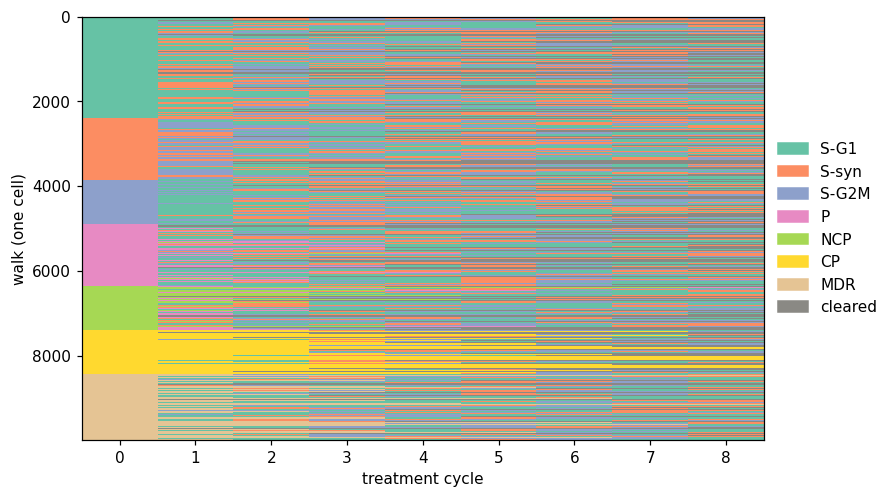

In [33]:
N_WALKS = 10000
starts = rng.choice(len(pi_mix), size=N_WALKS, p=pi_mix)
walks = np.array([random_walk(int(s0), P, N_CYCLES, rng) for s0 in starts])
walks = walks[np.argsort(walks[:, 0], kind="stable")]   # group rows by starting state

from matplotlib.colors import ListedColormap
fig, ax = plt.subplots(figsize=(8, 5))
ax.imshow(walks, cmap=ListedColormap([STATE_COLORS[s] for s in OUTCOMES]),
          vmin=-0.5, vmax=len(OUTCOMES) - 0.5, aspect="auto", interpolation="nearest")
ax.set_xlabel("treatment cycle"); ax.set_ylabel("walk (one cell)")
handles = [plt.Rectangle((0, 0), 1, 1, color=STATE_COLORS[s]) for s in OUTCOMES]
ax.legend(handles, OUTCOMES, loc="center left", bbox_to_anchor=(1, 0.5), frameon=False)
plt.show()

**Compare the two methods.** The fraction of walks in each state at cycle $t$
is an estimate of $\pi_t$. Plot both.

In [34]:
frac = np.array([[np.mean(walks[:, t] == j) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

sem = np.array([[np.std(walks[:, t] == j)/np.sqrt(len(walks)) for j in range(len(OUTCOMES))]
                 for t in range(N_CYCLES + 1)])

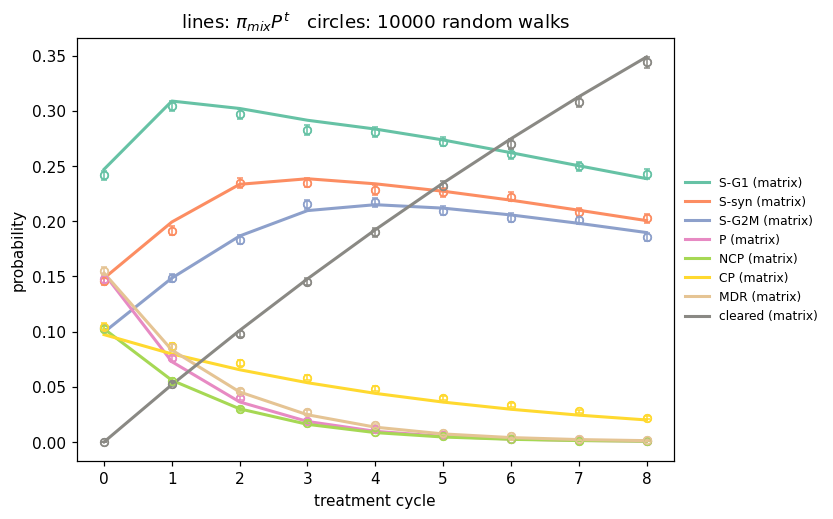

In [35]:
exact = evolve(pi_mix, P, N_CYCLES)
t = np.arange(N_CYCLES + 1)
fig, ax = plt.subplots(figsize=(7, 5))
for j, s in enumerate(OUTCOMES):
    ax.plot(t, exact[:, j], color=STATE_COLORS[s], lw=2, label=f"{s} (matrix)")
    ax.plot(t, frac[:, j], "o", color=STATE_COLORS[s], ms=5, mfc="none")
    ax.errorbar(t, frac[:, j], yerr=sem[:, j], fmt="o", color=STATE_COLORS[s],
            ms=5, mfc="none", capsize=2, elinewidth=1)
ax.set_xlabel("treatment cycle"); ax.set_ylabel("probability")
ax.set_title(f"lines: $\\pi_{{mix}} P^t$   circles: {N_WALKS} random walks")
ax.legend(loc="center left", bbox_to_anchor=(1, 0.5), frameon=False, fontsize=8)
plt.show()

We just simulated a tumor with 100 cells in it, and watched how it would evolve under no drug (drug holiday). Let's consider a different sized tumor.

<div class = 'alert alert-info'><b>Question:</b>

Re-run the last three cells with `N_WALKS = 10_000`. How does the gap between the circles and the lines change? Why?</div>

With N_WALKS = 10_000, the circles sit almost exactly on the lines, and the error bars become so small you can barely see them.
This happens because each circle is an average over the simulated cells, so it's an estimate of the true probability shown by the line. 

## 5. What's the probability a drug will clear a tumor?

We've seen in a few different ways how to understand the dynamics of cells within one tumor. We can simulate many tumors in a similar way. This allows us to interpret the likely paths of whole tumors under different treatment options and investigate things like how often cells switch states or linger in the same state.

In [31]:
def simulate_tumor(pi0, P, n_cells, n_cycles, rng):
    '''Return an array of the final state index of each of n_cells cells. Each
    cell's starting state is drawn from pi0.'''
    starts = rng.choice(len(pi0), size=n_cells, p=pi0)
    return np.array([random_walk(int(s0), P, n_cycles, rng)[-1] for s0 in starts])

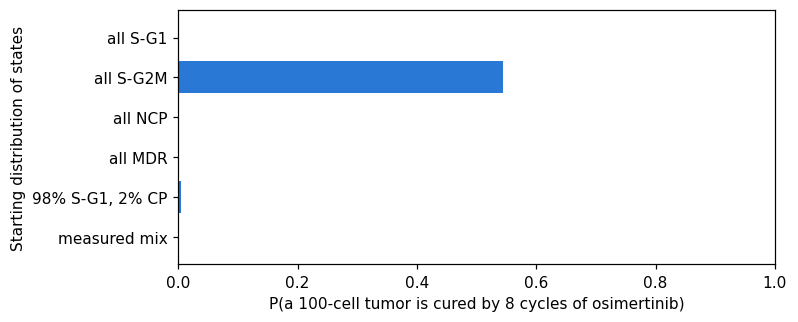

,P(cured),mean surviving cells,share of survivors that are CP
start,,,
all S-G1,0.000,7.805,0.0
all S-G2M,0.545,0.610,0.0
all NCP,0.000,6.690,0.0
all MDR,0.000,100.000,0.0
"98% S-G1, 2% CP",0.005,6.985,0.0
measured mix,0.000,18.955,0.0


In [36]:
N_CELLS, N_TUMORS = 100, 200
P_TUMOR, N_TUMOR_CYCLES = P_doc, 8      
scenarios = {
    "all S-G1":       basis("S-G1", P_hat),
    "all S-G2M":      basis("S-G2M", P_hat),
    "all NCP":         basis("NCP", P_hat),
    "all MDR":        basis("MDR", P_hat),
    "98% S-G1, 2% CP": 0.98 * basis("S-G1", P_hat) + 0.02 * basis("CP", P_hat),
    "measured mix":   pi_mix,
}
rows = []
for name, pi0 in scenarios.items():
    finals = np.array([simulate_tumor(pi0, P_TUMOR, N_CELLS, N_TUMOR_CYCLES, rng) for _ in range(N_TUMORS)])
    alive = (finals != OUTCOMES.index("cleared")).sum(axis=1)
    rows.append({"start": name,
                 "P(cured)": np.mean(alive == 0),
                 "mean surviving cells": alive.mean(),
                 "share of survivors that are CP":
                     (finals == OUTCOMES.index("CP")).sum() / max(alive.sum(), 1)})
results = pd.DataFrame(rows).set_index("start")

fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(results.index[::-1], results["P(cured)"][::-1], color="#2a78d6")
ax.set_xlim(0, 1)
ax.set_xlabel(f"P(a {N_CELLS}-cell tumor is cured by {N_TUMOR_CYCLES} cycles of osimertinib)")
ax.set_ylabel("Starting distribution of states")
plt.show()
results.round(3)

<div class="alert alert-info"> Try rerunning the above code with all docetaxel. What do the results look like? </div>

Docetaxel does much worse than osimertinib at curing tumors. Only the all S-G2M tumor gets cured with any regularity (about 55% of the time), while the MDR tumor and the mixed tumor are never cured, and most other tumors are cured less than 1% of the time. In almost every case, most of the cells that survive are MDR, because docetaxel can't kill MDR cells and even turns some other cells into MDR. So the tumor doesn't disappear; it becomes an MDR tumor.

## 6. Investigating the persister state

Something important about the persister cells (P and NCP) not yet included in this model is their ability to pick up *permanent* mutations that allow them to be *permanently resistant (PR).* In other words, if a cell stays in the persister state for too long, it will switch to a new absorbing state not in our data. We don't have this in our dataset, so we can't estimate the transition probability of P -> PR or NCP -> PR to add it to our matrix.

We know that if a cell stays in P or NCP for too long, it will eventually become permanently resistant. We will incorporate this into the model by assuming that **if a P or NCP cell stays in a persister state for 3 or more cycles, it will become permanently resistant.** So we want to look at the random walks of cells themselves and see what percentage of cells in a tumor stay in P or NCP for **3 or more** drug cycles. 

Let's look at 100 tumors of 1000 cells each under osimertinib treatment over 8 cycles. 

In [39]:

from scipy import stats

PERSISTER = [OUTCOMES.index("P"), OUTCOMES.index("NCP")]

# write a function that runs 1000 random walks and saves them
def run_walks(pi0, P_list, n_cells, rng):
    '''Run n_cells random walks. P_list holds one transition matrix per cycle,
    so mixed schedules work too. Returns an (n_cells, n_cycles + 1) array of state indices.'''
    walks = np.empty((n_cells, len(P_list) + 1), dtype=int)
    walks[:, 0] = rng.choice(len(pi0), size=n_cells, p=pi0)
    for t, P in enumerate(P_list):
        cdf = np.cumsum(P, axis=1)[walks[:, t]]      # each cell's row of the CDF
        u = rng.random((n_cells, 1))                  # inverse-CDF draw, all cells at once
        walks[:, t + 1] = np.minimum((u > cdf).sum(axis=1), len(pi0) - 1)
    return walks

# go through each random walk and check if a persister stays for 3+ consecutive cycles
def stuck_as_persister(walk, min_run=3):
    run = 0
    for s in walk:
        run = run + 1 if s in PERSISTER else 0
        if run >= min_run:
            return True
    return False

# count cells that stayed in a persister state out of total cells; repeat for all tumors
def fraction_resistant(pi0, P_list, n_cells=1000, n_tumors=100, rng=rng):
    fracs = []
    for _ in range(n_tumors):
        walks = run_walks(pi0, P_list, n_cells, rng)
        fracs.append(np.mean([stuck_as_persister(w) for w in walks]))
    return np.array(fracs)

# report mean +/- SEM and compare to the 10% threshold
def report(name, fracs, threshold=0.10):
    mean = fracs.mean()
    sem = fracs.std(ddof=1) / np.sqrt(len(fracs))
    lo, hi = mean - 1.96 * sem, mean + 1.96 * sem
    t_stat, p_val = stats.ttest_1samp(fracs, threshold, alternative="greater")
    print(f"{name}: mean = {mean:.4f} ± {sem:.4f} (SEM), 95% CI [{lo:.4f}, {hi:.4f}], "
          f"one-sided t-test p = {p_val:.3g}, tumors over 10%: {np.mean(fracs > threshold):.0%}")

fr_osi = fraction_resistant(pi_mix, [P_osi] * 8)
report("osimertinib, 8 cycles", fr_osi)



osimertinib, 8 cycles: mean = 0.1150 ± 0.0010 (SEM), 95% CI [0.1130, 0.1170], one-sided t-test p = 7.38e-27, tumors over 10%: 91%


In [40]:
M = {"O": P_osi, "D": P_doc, "H": P_holiday}
plans = {"Osimertinib alone": "O", "Docetaxel alone": "D",
         "Alternating OD": "OD", "Docetaxel + holiday": "DH"}
rows = []
for n in [4, 8, 12]:
    for name, pattern in plans.items():
        P_list = [M[pattern[i % len(pattern)]] for i in range(n)]
        fracs = fraction_resistant(pi_mix, P_list)
        rows.append({"cycles": n, "treatment": name,
                     "mean % resistant": 100 * fracs.mean(),
                     "% tumors over 10%": 100 * np.mean(fracs > 0.10)})
pd.DataFrame(rows).pivot(index="treatment", columns="cycles").round(1)


mean % resistant             % tumors over 10%            
cycles                            4     8     12                4     8     12
treatment                                                                     
Alternating OD                  10.1  10.8  10.6              49.0  75.0  73.0
Docetaxel + holiday              8.2   9.9  10.2               0.0  43.0  61.0
Docetaxel alone                  8.6   9.2   9.1               4.0  17.0  13.0
Osimertinib alone               11.1  11.5  11.8              87.0  91.0  95.0

<div class="alert alert-info"> What percentage of tumors under the following treatments have more than 10% permanently resistant cells? How does this change as you increase the number of cycles?

- Osimertinib alone
- Doxetaxel alone
- Alternating OD
- Doxetaxel with drug holiday
</div>

Osimertinib alone is the worst. 87% of tumors have more than 10% permanently resistant cells after 4 cycles, rising to 95% after 12. Alternating OD goes from 49% to about 75% by 8 cycles, and docetaxel with a drug holiday starts at 0% but climbs to 61% by 12 cycles. Docetaxel alone stays lowest, at 4% to 17%, and levels off after 8 cycles, though it leaves behind MDR cells it can't kill. In general, more cycles means more tumors cross the 10% line, because each extra cycle gives persister cells another chance to stay stuck and become permanently resistant. So shorter treatment is better.